# IST_robot：末端 15 Hz 固定基座升力实验

沿用原实验的机器人、被动羽化、气动力与电机参数，仅调整输入轴转速指令。
16∶1 减速下的理想输入角速度为 `15 × 2π × 16 ≈ 1507.96 rad/s`。
比例调速有负载转速误差，因此通过实际完整周期测量修正指令，并记录在 `calibration.json`。
频率按完整曲柄周期计算；升力为左右翼气动力的世界坐标 Fz，正值向上。
排除前 0.6 s 后，使用完整周期边界内的时间积分求平均。
电机与气动参数未做实机标定，这里报告的是当前模型的仿真结果。

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
from IPython.display import display, Image, Video, Markdown

here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / 'flapsim' / 'simulator.py').is_file())
EXPERIMENT = ROOT / 'experiments' / 'fixbase'
sys.path.insert(0, str(EXPERIMENT))
from run_15hz import main, cycle_statistics, plot_lift
RUN_SIMULATION = False  # 改成 True 可重新调速并运行；默认读取已保存的真实数据。
if RUN_SIMULATION:
    main()
OUTPUT = EXPERIMENT / 'results_15hz'
with np.load(OUTPUT / 'measurements.npz') as saved:
    data = {k: saved[k] for k in saved.files}
summary = json.loads((OUTPUT / 'summary.json').read_text())
lift = json.loads((OUTPUT / 'lift_summary.json').read_text())
recomputed = cycle_statistics(data, after=.6)
assert np.isclose(recomputed['mean_lift_N'], lift['mean_lift_N'])
assert abs(lift['measured_wing_frequency_hz'] - 15) < .05
assert summary['max_base_pose_error'] == 0
assert not any(summary['numerical_warnings'])
plot_lift(data, lift)
print(f"实测末端频率：{lift['measured_wing_frequency_hz']:.5f} Hz")
print(f"平均总升力：{lift['mean_lift_N']:.6f} N = {lift['mean_lift_mN']:.3f} mN")
print('完整周期数：', lift['complete_cycles'])
print('统计时间区间 [s]：', lift['averaging_interval_s'])
print('各周期升力均值范围 [N]：', lift['cycle_lift_min_max_N'])
print('实际电机速度指令 [rad/s]：', lift['motor_command_rad_s'])

实测末端频率：14.99925 Hz
平均总升力：0.089252 N = 89.252 mN
完整周期数： 20
统计时间区间 [s]： [0.6040984312933969, 1.9374985077352682]
各周期升力均值范围 [N]： [0.08903532932644061, 0.08948207522521423]
实际电机速度指令 [rad/s]： 1872.5143410542667


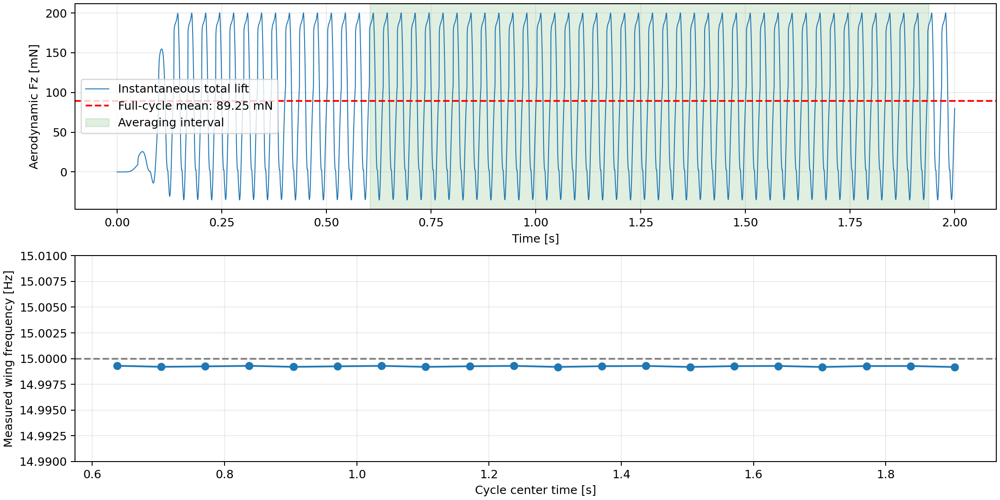

In [2]:
display(Image(filename=str(OUTPUT / 'lift_15hz.png')))

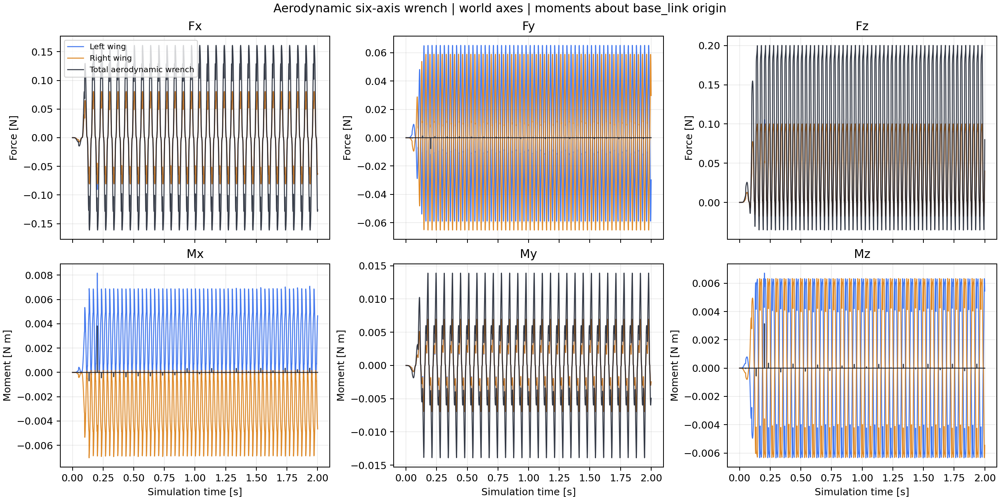

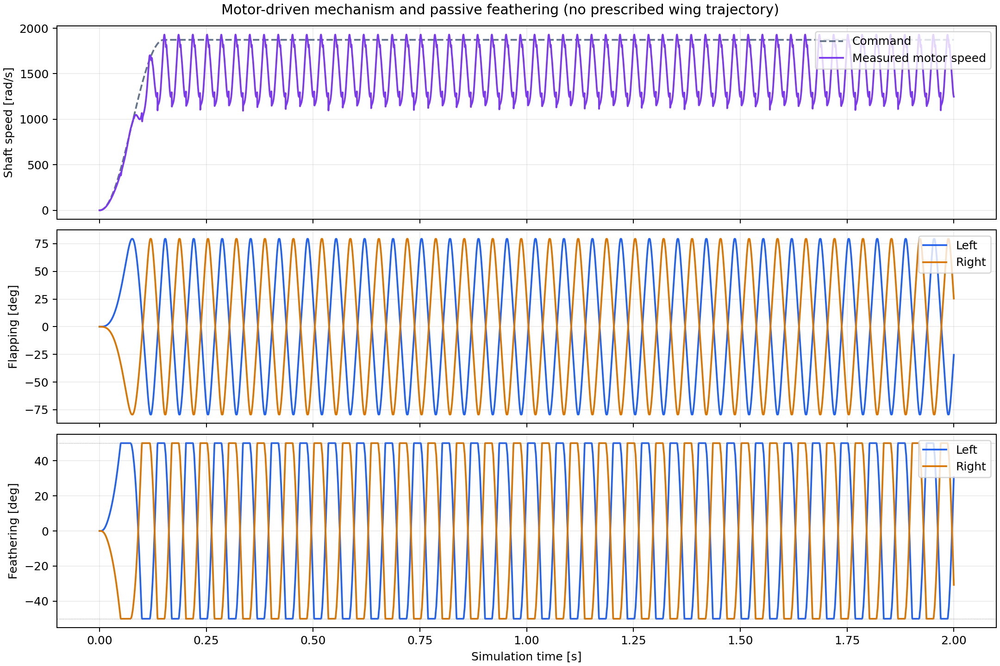

In [3]:
display(Image(filename=str(OUTPUT / 'wrench_6d.png')))
display(Image(filename=str(OUTPUT / 'joint_motion.png')))

In [4]:
display(Video(str(OUTPUT / 'fixbase.mp4'), embed=True, width=1100, html_attributes='controls loop muted'))

原始数据见 `results_15hz/measurements.csv` 与 `.npz`。
六维顺序为 Fx、Fy、Fz、Mx、My、Mz，力矩参考 base_link 原点。
`aero_*` 为气动力；`fixture_*` 为机器人作用于支座的总载荷，两者不混用。
完整周期统计见 `lift_summary.json`；视频以 250 仿真帧/s 捕获、30 fps 编码，约 8.33 倍慢放。
复现命令：`python experiments/fixbase/run_15hz.py`。